In [72]:
!git clone https://github.com/lvemilio/aesthetic-unsplash-image-analysis.git
%cd aesthetic-unsplash-image-analysis

import pandas as pd
import numpy as np

df = pd.read_parquet("data/ava_cleaned_features.parquet")
print("Dataset shape:", df.shape)
print("Columns:", df.columns.tolist())
df.head()

Cloning into 'aesthetic-unsplash-image-analysis'...
remote: Enumerating objects: 29, done.
remote: Counting objects: 100% (2/2), done.
remote: Compressing objects: 100% (2/2), done.
remote: Total 29 (delta 0), reused 0 (delta 0), pack-reused 27 (from 2)
Receiving objects: 100% (29/29), 105.92 MiB | 24.38 MiB/s, done.
Resolving deltas: 100% (5/5), done.
Updating files: 100% (10/10), done.
/content/aesthetic-unsplash-image-analysis/aesthetic-unsplash-image-analysis/aesthetic-unsplash-image-analysis/aesthetic-unsplash-image-analysis/aesthetic-unsplash-image-analysis/aesthetic-unsplash-image-analysis/aesthetic-unsplash-image-analysis/aesthetic-unsplash-image-analysis/aesthetic-unsplash-image-analysis/aesthetic-unsplash-image-analysis/aesthetic-unsplash-image-analysis/aesthetic-unsplash-image-analysis
Dataset shape: (20420, 7)
Columns: ['image_id', 'mean_score', 'std_score', 'total_votes', 'rating_counts', 'structural_features', 'clip_embedding']


,image_id,mean_score,std_score,total_votes,rating_counts,structural_features,clip_embedding
0,111875,5.807692,1.670312,208,"[1, 2, 7, 34, 53, 50, 28, 19, 7, 7]","[0.08417275547981262, 0.15377438068389893, 1.2...","[0.0016924834344536066, -0.014361293986439705,..."
1,287132,4.852174,1.671986,230,"[7, 12, 22, 52, 63, 42, 19, 8, 3, 2]","[0.043213702738285065, 0.04941313713788986, 1....","[-0.0006810238119214773, 0.012423894368112087,..."
2,712748,4.763514,1.275346,148,"[1, 5, 17, 33, 54, 29, 6, 2, 1, 0]","[0.4837675094604492, 0.31897664070129395, 1.02...","[0.0030595441348850727, 0.027914635837078094, ..."
3,60556,5.918239,1.504578,159,"[0, 3, 5, 14, 41, 43, 34, 11, 5, 3]","[0.48542794585227966, 0.24875479936599731, 0.9...","[0.041529785841703415, 0.01705673150718212, -0..."
4,522313,5.065089,1.192392,169,"[2, 1, 5, 39, 74, 33, 10, 3, 1, 1]","[0.4340306222438812, 0.19774529337882996, 0.97...","[-0.019383734092116356, 0.0010034549050033092,..."


In [73]:
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
import numpy as np

# 1. Unpack the lists stored in the DataFrame cells into flat 2D matrices
clip_matrix = np.vstack(df['clip_embedding'].values)
struct_matrix = np.vstack(df['structural_features'].values)
std_matrix = df[['std_score']].to_numpy(dtype=np.float32)

# 2. Combine them horizontally into one massive numerical matrix
X_raw = np.hstack((clip_matrix, struct_matrix, std_matrix))
print(f"Final extracted matrix shape: {X_raw.shape}")

# 3. Standardize features (zero mean, unit variance)
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X_raw)

# 4. Apply PCA (aligning with Emils & Imola's PCA step)
n_components = min(20, X_scaled.shape[1])
pca = PCA(n_components=n_components, random_state=42)
X_features = pca.fit_transform(X_scaled)
print(f"Explained variance by {n_components} components: {np.sum(pca.explained_variance_ratio_):.2%}")

Final extracted matrix shape: (20420, 525)
Explained variance by 20 components: 26.76%


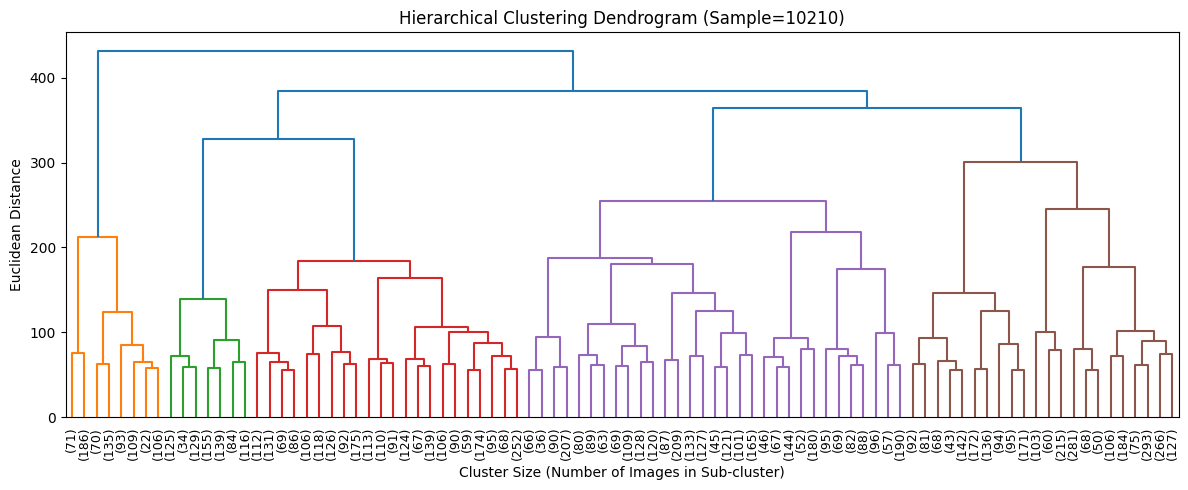

In [74]:
import matplotlib.pyplot as plt
from scipy.cluster.hierarchy import dendrogram, linkage
from sklearn.cluster import AgglomerativeClustering
import numpy as np

np.random.seed(42)
size=10210
sample_size = min(size, X_features.shape[0])
sample_idx = np.random.choice(X_features.shape[0], sample_size, replace=False)
X_sample = X_features[sample_idx]

plt.figure(figsize=(12, 5))
Z = linkage(X_sample[:size], method='ward')
dendrogram(Z, truncate_mode='lastp', p=90, leaf_rotation=90., leaf_font_size=9.)
plt.title(f"Hierarchical Clustering Dendrogram (Sample={sample_size})")
plt.xlabel("Cluster Size (Number of Images in Sub-cluster)")
plt.ylabel("Euclidean Distance")
plt.tight_layout()
plt.savefig("hierarchical_dendrogram.png", dpi=300)
plt.show()

In [75]:
from scipy.spatial.distance import cdist
from sklearn.metrics import davies_bouldin_score, silhouette_score
import pandas as pd

def run_cure_clustering(X_all, X_samp, samp_indices, n_clusters=8, n_reps=5, alpha=0.2):
    hc = AgglomerativeClustering(n_clusters=n_clusters, metric='euclidean', linkage='ward')
    samp_labels = hc.fit_predict(X_samp)

    representatives = []
    rep_cluster_labels = []

    for c_id in range(n_clusters):
        mask = (samp_labels == c_id)
        cluster_pts = X_samp[mask]
        centroid = np.mean(cluster_pts, axis=0)

        chosen_pts = []
        for _ in range(min(n_reps, len(cluster_pts))):
            if not chosen_pts:
                dists = np.linalg.norm(cluster_pts - centroid, axis=1)
                idx = np.argmax(dists)
            else:
                dists = np.min(cdist(cluster_pts, np.array(chosen_pts)), axis=1)
                idx = np.argmax(dists)

            chosen_pts.append(cluster_pts[idx])
            shrunk_pt = cluster_pts[idx] + alpha * (centroid - cluster_pts[idx])
            representatives.append(shrunk_pt)
            rep_cluster_labels.append(c_id)

    representatives = np.array(representatives)
    rep_cluster_labels = np.array(rep_cluster_labels)

    all_dists = cdist(X_all, representatives, metric='euclidean')
    full_labels = rep_cluster_labels[np.argmin(all_dists, axis=1)]
    return full_labels

results = []
for k in [5, 8, 10, 12]:
    labels = run_cure_clustering(X_features, X_sample, sample_idx, n_clusters=k)
    db_idx = davies_bouldin_score(X_features, labels)
    sil = silhouette_score(X_features, labels, sample_size=min(5000, X_features.shape[0]), random_state=42)
    results.append({"k": k, "Davies-Bouldin (Lower=Better)": db_idx, "Silhouette (Higher=Better)": sil})

df_eval = pd.DataFrame(results)
print(df_eval)

    k  Davies-Bouldin (Lower=Better)  Silhouette (Higher=Better)
0   5                       4.358838                    0.022794
1   8                       4.370505                    0.007142
2  10                       4.090518                    0.014202
3  12                       4.351093                    0.002791


In [76]:
best_idx = df_eval["Davies-Bouldin (Lower=Better)"].idxmin()
best_k = int(df_eval.loc[best_idx, "k"])
print(f"Automatically selected optimal clusters (k): {best_k}")

df["cure_cluster"] = run_cure_clustering(X_features, X_sample, sample_idx, n_clusters=best_k)

cluster_profile = df.groupby("cure_cluster")[['mean_score']].mean()
print("Cluster Profiles (Aesthetic Score):")
print(cluster_profile)

def find_top_similar_in_cluster(query_idx, top_k=5):
    c_id = df.loc[query_idx, "cure_cluster"]
    cluster_rows = df[df["cure_cluster"] == c_id].index.to_numpy()
    dists = cdist(X_features[query_idx:query_idx+1], X_features[cluster_rows], metric='euclidean').flatten()
    nearest_local = np.argsort(dists)[1:top_k+1]
    return df.iloc[cluster_rows[nearest_local]][['image_id', 'mean_score', 'cure_cluster']]

print("\nTop similar images to row 0 within its cluster:")
print(find_top_similar_in_cluster(0))

Automatically selected optimal clusters (k): 10
Cluster Profiles (Aesthetic Score):
              mean_score
cure_cluster            
0               5.473062
1               5.312776
2               5.355068
3               5.656663
4               5.388230
5               5.369764
6               5.475946
7               5.207953
8               5.487673
9               5.312362

Top similar images to row 0 within its cluster:
      image_id  mean_score  cure_cluster
3546    479049    5.166667             0
11259   688803    6.364103             0
3084    741963    6.047337             0
14490   812897    4.985075             0
853     744375    5.111940             0


In [77]:
from sklearn.model_selection import KFold
from sklearn.metrics import mean_squared_error
from sklearn.cluster import KMeans, AgglomerativeClustering
from scipy.spatial.distance import cdist
import numpy as np

np.random.seed(42)
kf = KFold(n_splits=2, shuffle=True, random_state=42)
y_true = df['mean_score'].to_numpy()

cure_rmses, kmeans_rmses = [], []
# Scale the sample size proportionally for the half-sized training fold
fold_sample_size = min(max(1, sample_size // 2), len(X_features) // 2)

for train_idx, test_idx in kf.split(X_features):
    X_tr, X_te = X_features[train_idx], X_features[test_idx]
    y_tr, y_te = y_true[train_idx], y_true[test_idx]

    # --- 1. CURE Evaluation (Dynamic sample_size and best_k) ---
    samp_idx = np.random.choice(len(X_tr), fold_sample_size, replace=False)
    hc = AgglomerativeClustering(n_clusters=best_k, metric='euclidean', linkage='ward')
    tr_labels = hc.fit_predict(X_tr[samp_idx])

    reps, rep_labels = [], []
    for c_id in range(best_k):
        mask = (tr_labels == c_id)
        cluster_pts = X_tr[samp_idx][mask]
        if len(cluster_pts) == 0:
            continue
        centroid = np.mean(cluster_pts, axis=0)
        chosen_pts = []
        for _ in range(min(5, len(cluster_pts))):
            if not chosen_pts:
                dists = np.linalg.norm(cluster_pts - centroid, axis=1)
                idx = np.argmax(dists)
            else:
                dists = np.min(cdist(cluster_pts, np.array(chosen_pts)), axis=1)
                idx = np.argmax(dists)
            chosen_pts.append(cluster_pts[idx])
            reps.append(cluster_pts[idx] + 0.2 * (centroid - cluster_pts[idx]))
            rep_labels.append(c_id)

    reps = np.array(reps)
    rep_labels = np.array(rep_labels)

    tr_assigned = rep_labels[np.argmin(cdist(X_tr, reps), axis=1)]
    cure_cluster_means = {c: y_tr[tr_assigned == c].mean() for c in range(best_k)}
    test_rep_labels = rep_labels[np.argmin(cdist(X_te, reps), axis=1)]
    y_pred_cure = np.array([cure_cluster_means.get(c, y_tr.mean()) for c in test_rep_labels])
    cure_rmses.append(np.sqrt(mean_squared_error(y_te, y_pred_cure)))

    # --- 2. K-Means Evaluation (Dynamic best_k) ---
    km = KMeans(n_clusters=best_k, random_state=42, n_init=5).fit(X_tr)
    km_cluster_means = {c: y_tr[km.labels_ == c].mean() for c in range(best_k)}
    test_km_labels = km.predict(X_te)
    y_pred_km = np.array([km_cluster_means.get(c, y_tr.mean()) for c in test_km_labels])
    kmeans_rmses.append(np.sqrt(mean_squared_error(y_te, y_pred_km)))

print(f"Configuration -> Sample Size: {sample_size} (Fold Sample: {fold_sample_size}) | Best k: {best_k}")
print(f"CURE (k={best_k}) 2-Fold CV RMSE:    {np.mean(cure_rmses):.4f}")
print(f"K-Means (k={best_k}) 2-Fold CV RMSE: {np.mean(kmeans_rmses):.4f}")

Configuration -> Sample Size: 10210 (Fold Sample: 5105) | Best k: 10
CURE (k=10) 2-Fold CV RMSE:    0.7216
K-Means (k=10) 2-Fold CV RMSE: 0.7149
